# Modelo y resultados

![Arquitectura](../figures/architecture.png)

*Diagrama de la arquitectura hecho con ayuda de IA.*

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import confusion_matrix, f1_score
from IPython.display import Audio, display

sys.path.insert(0, str(Path.cwd().parent))
from src.config import CLASSES, MODELS_DIR, N_CLASSES, SAMPLE_RATE, SEED, SILENCE
from src.data import NoiseBank, load_noise, load_split, mix
from src.evaluate import CONDITIONS, SNRS, accuracy_table, predict_labels, test_sets
from src.features import LogMel
from src.model import build_model
from src.train import LAMBDAS, load_model, train_model

keras.utils.set_random_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.18.1 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Clips per split: {'train': 20875, 'dev': 2707, 'test': 2707}


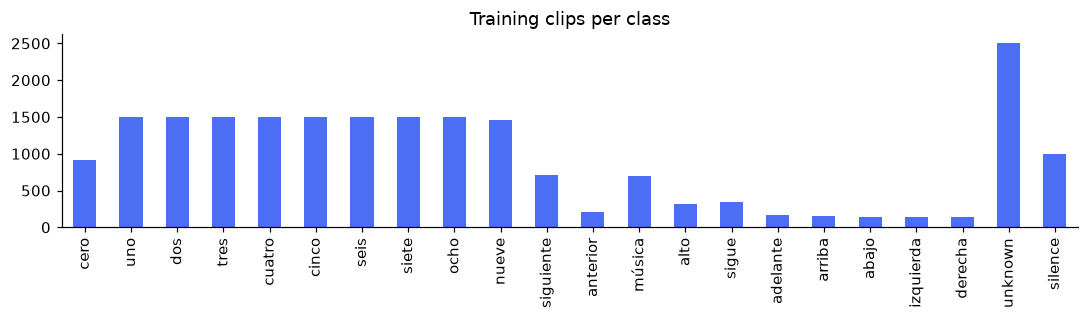

Example: "tres"


In [2]:
x_train, y_train = load_split("train")
x_dev, y_dev = load_split("dev")
x_test, y_test = load_split("test")
noise = load_noise()

counts = pd.DataFrame({"train": np.bincount(y_train, minlength=N_CLASSES),
                       "dev": np.bincount(y_dev, minlength=N_CLASSES),
                       "test": np.bincount(y_test, minlength=N_CLASSES)}, index=CLASSES)
print("Clips per split:", {split: int(counts[split].sum()) for split in counts})
counts["train"].plot.bar(figsize=(10, 3), color="#4C6EF5", title="Training clips per class")
plt.tight_layout()
plt.show()

example = int(np.where(y_train == CLASSES.index("tres"))[0][0])
print('Example: "tres"')
display(Audio(x_train[example], rate=SAMPLE_RATE))

In [3]:
banks = {split: NoiseBank(audio) for split, audio in noise.items()}
print({split: f"{len(bank.windows)} windows" for split, bank in banks.items()})

{'train': '43696 windows', 'dev': '14895 windows', 'test': '14773 windows'}


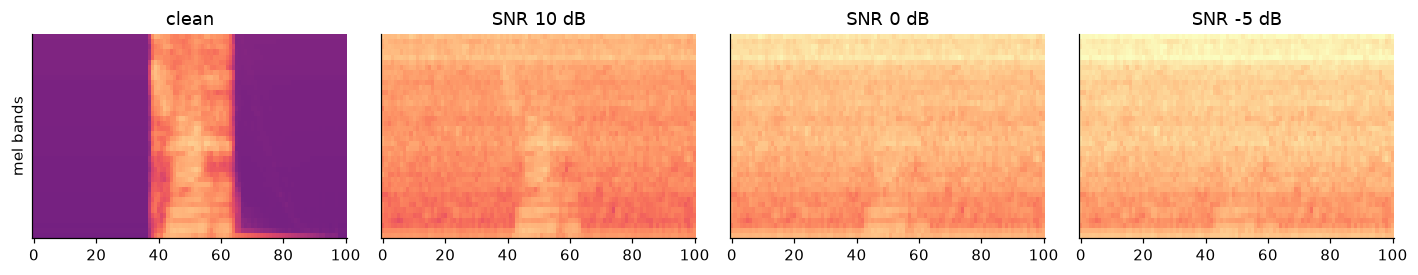

In [4]:
logmel = LogMel(name="logmel")
logmel.adapt(x_train[y_train != SILENCE][:6000])

rng = np.random.default_rng(1)
one_noise = banks["train"].sample(1, rng)
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, snr in zip(axes, [None, 10, 0, -5]):
    audio = x_train[example:example + 1]
    if snr is not None:
        audio = mix(audio, one_noise, np.array([snr]), np.array([-30.0]))
    ax.imshow(logmel(audio)[0, :, :, 0], origin="lower", aspect="auto", cmap="magma", vmin=-3, vmax=3)
    ax.set_title("clean" if snr is None else f"SNR {snr} dB")
    ax.set_yticks([])
axes[0].set_ylabel("mel bands")
plt.tight_layout()
plt.show()

In [5]:
print(f"Parameters of the base CNN: {build_model(False).count_params():,}")
print(f"Parameters of the multitask model (with decoder): {build_model(True).count_params():,}")

Parameters of the base CNN: 290,694
Parameters of the multitask model (with decoder): 388,167


In [6]:
models = {}
for name in LAMBDAS:
    weights = MODELS_DIR / f"{name}.weights.h5"
    if weights.exists():
        models[name] = load_model(name)
        print(f"{name}: weights loaded from models/{weights.name}")
    else:
        models[name] = train_model(name, x_train, y_train, x_dev, y_dev, noise)

base: weights loaded from models/base.weights.h5
multitask: weights loaded from models/multitask.weights.h5


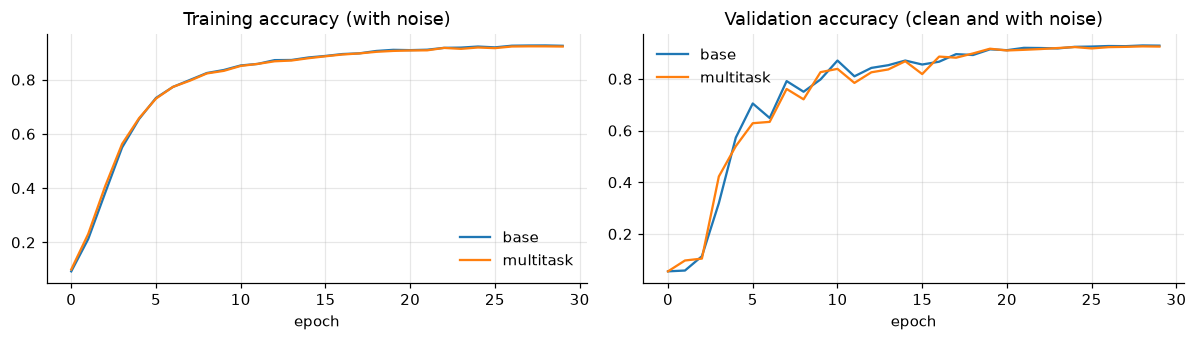

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for name, lam in LAMBDAS.items():
    history = json.loads((MODELS_DIR / f"{name}_history.json").read_text())
    key = "label_accuracy" if lam > 0 else "accuracy"
    axes[0].plot(history[key], label=name)
    axes[1].plot(history[f"val_{key}"], label=name)
axes[0].set_title("Training accuracy (with noise)")
axes[1].set_title("Validation accuracy (clean and with noise)")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

In [8]:
x_eval = test_sets(x_test, banks["test"])
predictions = {name: {condition: predict_labels(model, audio) for condition, audio in x_eval.items()}
               for name, model in models.items()}

accuracy = accuracy_table(predictions, y_test)
f1 = pd.DataFrame({name: {condition: f1_score(y_test, labels, average="macro") for condition, labels in by_cond.items()}
                   for name, by_cond in predictions.items()}).T

print("Accuracy (%)")
display(accuracy.round(1))
print("Macro F1 (%)")
display((100 * f1).round(1))

Accuracy (%)


,clean,20 dB,10 dB,5 dB,0 dB,-5 dB,noisy average
base,94.4,93.6,92.1,90.3,85.6,77.2,87.8
multitask,94.2,93.4,92.4,90.2,86.0,77.1,87.8


Macro F1 (%)


,clean,20 dB,10 dB,5 dB,0 dB,-5 dB
base,93.3,92.5,90.4,88.8,83.5,74.0
multitask,94.0,92.7,91.4,88.2,83.8,73.1


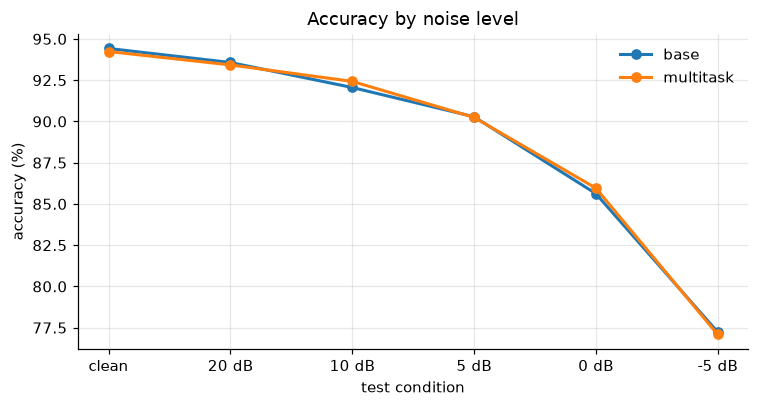

In [9]:
plt.figure(figsize=(7, 3.8))
for name in models:
    plt.plot(list(CONDITIONS), accuracy.loc[name, list(CONDITIONS)], marker="o", lw=2, label=name)
plt.ylabel("accuracy (%)")
plt.xlabel("test condition")
plt.title("Accuracy by noise level")
plt.grid(alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

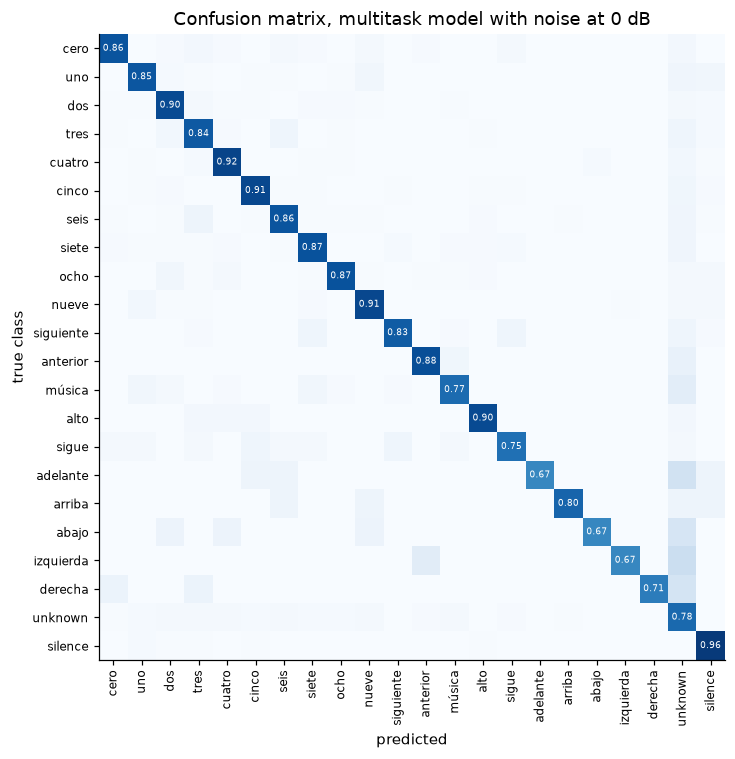

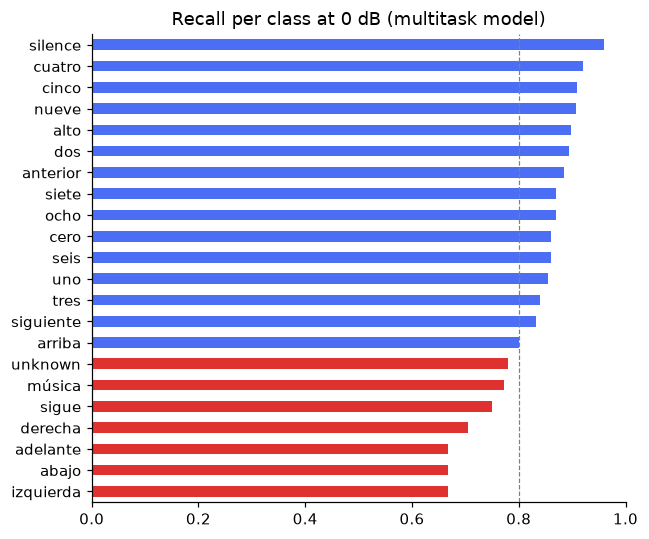

In [10]:
best = accuracy["noisy average"].idxmax()
matrix = confusion_matrix(y_test, predictions[best]["0 dB"], labels=range(N_CLASSES))
matrix = matrix / matrix.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES), CLASSES, rotation=90, fontsize=8)
ax.set_yticks(range(N_CLASSES), CLASSES, fontsize=8)
for k in range(N_CLASSES):
    ax.text(k, k, f"{matrix[k, k]:.2f}", ha="center", va="center", fontsize=6,
            color="white" if matrix[k, k] > 0.5 else "black")
ax.set_xlabel("predicted")
ax.set_ylabel("true class")
ax.set_title(f"Confusion matrix, {best} model with noise at 0 dB")
plt.tight_layout()
plt.show()

recall = pd.Series(np.diag(matrix), CLASSES).sort_values()
colors = ["#E03131" if value < 0.8 else "#4C6EF5" for value in recall]
recall.plot.barh(figsize=(6, 5), color=colors, title=f"Recall per class at 0 dB ({best} model)")
plt.xlim(0, 1)
plt.axvline(0.8, color="grey", ls="--", lw=0.8)
plt.tight_layout()
plt.show()

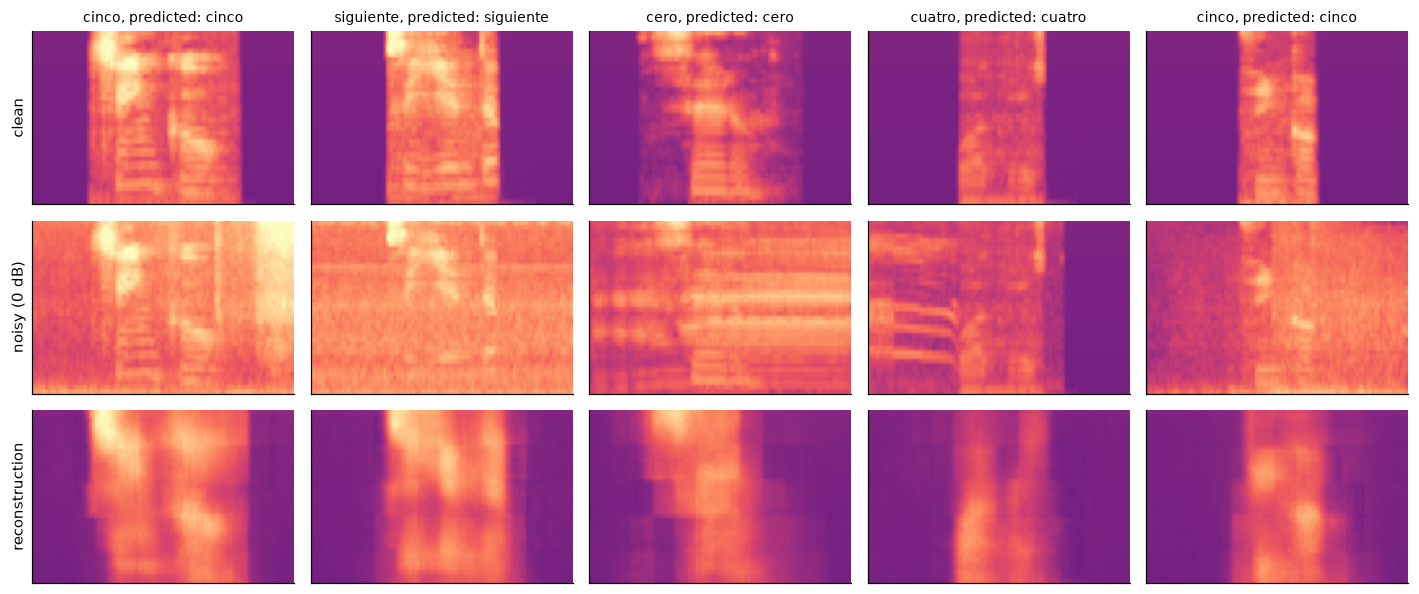

,clean,20 dB,10 dB,5 dB,0 dB,-5 dB
noisy input error,0.185,1.107,1.726,2.116,2.565,3.076
reconstruction error,0.087,0.116,0.151,0.181,0.224,0.287


In [11]:
multitask = models["multitask"]
to_logmel = multitask.get_layer("logmel")
picked = np.random.default_rng(3).choice(np.where(y_test < 20)[0], 5, replace=False)
output = multitask.predict(x_eval["0 dB"][picked], verbose=0)
rows = [("clean", to_logmel(x_test[picked])),
        ("noisy (0 dB)", to_logmel(x_eval["0 dB"][picked])),
        ("reconstruction", output["reconstruction"])]

fig, axes = plt.subplots(3, 5, figsize=(13, 5.5))
for col in range(5):
    for row, (title, images) in enumerate(rows):
        axes[row, col].imshow(np.asarray(images)[col, :, :, 0], origin="lower", aspect="auto",
                              cmap="magma", vmin=-3, vmax=3)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(title)
    true_word = CLASSES[y_test[picked[col]]]
    predicted = CLASSES[output["label"][col].argmax()]
    axes[0, col].set_title(f"{true_word}, predicted: {predicted}", fontsize=9)
plt.tight_layout()
plt.show()


def in_batches(function, audio, size=512):
    return np.concatenate([np.asarray(function(audio[i:i + size])) for i in range(0, len(audio), size)])


clean = in_batches(to_logmel, x_test)
errors = {}
for condition in CONDITIONS:
    noisy = in_batches(to_logmel, x_eval[condition])
    rebuilt = multitask.predict(x_eval[condition], batch_size=512, verbose=0)["reconstruction"]
    errors[condition] = {"noisy input error": ((noisy - clean) ** 2).mean(),
                         "reconstruction error": ((rebuilt - clean) ** 2).mean()}
display(pd.DataFrame(errors).round(3))

In [12]:
model = models[best]
chosen = np.random.default_rng(5).choice(len(y_test), 10, replace=False)
probability = model.predict(x_eval["0 dB"][chosen], verbose=0)["label"]

table = pd.DataFrame({
    "true": [CLASSES[y_test[i]] for i in chosen],
    "predicted": [CLASSES[p.argmax()] for p in probability],
    "confidence": probability.max(axis=1).round(2),
    "second guess": [CLASSES[p.argsort()[-2]] for p in probability],
})
table["correct"] = table["true"] == table["predicted"]
display(table)
print("Audio of the first clip, with noise at 0 dB:")
display(Audio(x_eval["0 dB"][chosen[0]], rate=SAMPLE_RATE))

,true,predicted,confidence,second guess,correct
0,uno,uno,0.40,unknown,True
1,siete,siete,0.92,izquierda,True
2,silence,silence,0.91,dos,True
3,dos,dos,0.58,ocho,True
4,seis,seis,0.90,siete,True
5,siguiente,siguiente,0.75,siete,True
6,cero,cero,0.93,izquierda,True
7,ocho,ocho,0.98,dos,True
8,uno,uno,0.76,unknown,True
9,alto,alto,0.65,cinco,True


Audio of the first clip, with noise at 0 dB:
